In [1]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics # 분류와 숫자 예측에 사용하는 모델 모음,모델의 예측 성능을 평가하는 도구 모음
from sklearn.neighbors import KNeighborsClassifier  #분류(가까운 이웃 데이터를 참고해 종류를 분류)
from sklearn.neighbors import KNeighborsRegressor   #예측(가까운 이웃데이터를 참고해 숫자를 예측)

from sklearn.preprocessing import PolynomialFeatures # 다항특성 (x², x₁ × x₂ 같은 특성을 추가)
from sklearn.preprocessing import OneHotEncoder      # 원핫인코딩(문자형 번주를 0과1로 변환)

from sklearn.linear_model import LinearRegression   #예측 (입력과 결과의 선형관례를 학습해 숫자를 예측)
from sklearn.linear_model import Ridge              #릿지 (계수가 지나치게 커지는 것을 억제하는 선형 회귀)
from sklearn.linear_model import Lasso              #라쏘 (일부 계수를 0으로 만들어 특성 선택에도 활용하는 선형 회귀)
from sklearn.linear_model import LogisticRegression #분류
from sklearn.linear_model import SGDClassifier

from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위 (실제값과 예측값의 차이를 절댓값으로 구한 뒤 평균 계산)
from sklearn.preprocessing import StandardScaler # 표준화 (각 특성을 평균 0, 표준편차 1 기준으로 표준화)
from sklearn.model_selection import train_test_split #(데이터를 학습용과 평가용으로 분리)
from scipy.special import expit                     #exip:이진분류함수
from scipy.special import softmax                   #softmax: 다중분류함수

# 결정트리
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree                  #그래프지원

# 교차검증
from sklearn.model_selection import cross_validate      # 자동 반복

# 분할기
from sklearn.model_selection import StratifiedKFold

from sklearn.model_selection import GridSearchCV

In [2]:
# 데이터 가져오기
wine = pd.read_csv('data/wine.csv')
wine.head(2)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [3]:
# data,label 저장
data = wine[wine.columns[:-1]].values
label = wine['class'].values

# 데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label,test_size=0.2,random_state=42)

1. 그리드 서치
- for문 사용하는것 다 사용할수 있음

In [4]:
params={
    'max_depth':range(5,20,1),
    'min_impurity_decrease':np.arange(0.0001,0.001,0.0001),
    'min_samples_split':range(2,100,10)
}
# n_jobs=-1 : 모든 cpu core를 사용해서 처리, return_train_score=True하면  train정확도도 알수있음
gs= GridSearchCV(DecisionTreeClassifier(random_state=42), params, n_jobs=-1,\
                return_train_score=True)
gs.fit(train_data, train_label)

# best_estimator_: 가장 좋은 검증 점수를 얻은 설정으로 학습된 모델
dt = gs.best_estimator_ #위 학습한 것에 가장 좋은 모델을 뽑아달라
print('train정확도:', dt.score(train_data,train_label))
print('test정확도:', dt.score(test_data,test_label))


# cv_results_ : 교차 검증 결과가 담긴 속성(정해짐)
# ['mean_train_score'] : 결과에서 평균 학습 점수를 찾는 키(정해짐)
print("가장좋은 파라미터:", gs.best_params_)
print(gs.cv_results_['mean_train_score'])
print(gs.cv_results_['mean_test_score'])

# dt = DecisionTreeClassifier(max_depth=3,random_state=42)
# dt.fit(train_data,train_label)

train정확도: 0.892053107562055
test정확도: 0.8615384615384616
가장좋은 파라미터: {'max_depth': 14, 'min_impurity_decrease': np.float64(0.0004), 'min_samples_split': 12}
[0.86968438 0.86963628 0.86963628 ... 0.8779107  0.87781448 0.87637131]
[0.85780355 0.85799604 0.85799604 ... 0.86126601 0.86165063 0.86357629]


In [5]:
len(gs.cv_results_['mean_train_score'])

1350

In [6]:
alist=list(range(1,1351))

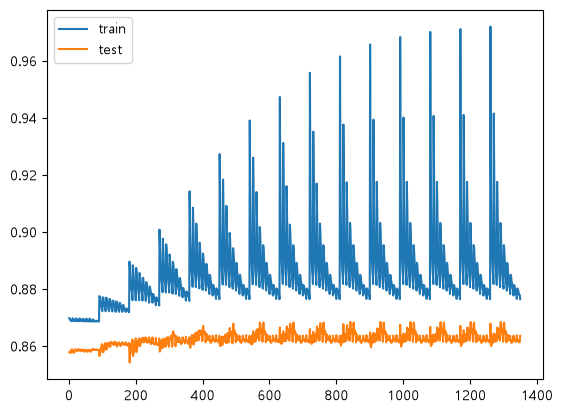

In [7]:
# 그래프그리기
plt.plot(alist, gs.cv_results_['mean_train_score'])
plt.plot(alist, gs.cv_results_['mean_test_score'])

plt.legend(['train','test'])

plt.show()